# Two cells: ignore, adhere or merge

Two cells of 27 elements each start side by side, separated by a gap of 1.3 equilibrium distances
(inside the interaction range of 2.5), and relax without noise. Elements of the same cell interact through
the *intra*-cellular well, elements of different cells through the *inter*-cellular well. The two wells have
the same shape and differ only in depth (see `pair_potential.ipynb`), so one number decides the outcome:

$$\text{ratio} = \frac{u_0^\mathrm{inter}}{u_0^\mathrm{intra}}$$

All data in this notebook is produced by the C++ solver; nothing is re-implemented in Python.
The files in `data/` are the output of the `two_cells` example:

```bash
for ratio in 0 0.5 1; do
  build/gcc-debug/mechanics/micromechanics/examples/mechanics.micromechanics.two_cells $ratio 20 20 \
      > mechanics/micromechanics/docs/notebooks/data/two_cells_ratio_$ratio.csv
done
```

Parameters are the defaults ($r_\mathrm{eq} = 1$, $\rho = 2$, $u_0^\mathrm{intra} = 1$, $\eta = 1$) with $\Delta t = 0.002$.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

ratios = ["0", "0.5", "1"]
labels = {"0": "ratio 0: no inter-cellular well", "0.5": "ratio 0.5: default", "1": "ratio 1: equal wells"}
cell_colors = ["tab:blue", "tab:orange"]


def load(ratio):
    table = np.genfromtxt(Path("data") / f"two_cells_ratio_{ratio}.csv", delimiter=",", names=True, skip_header=1)
    times = np.unique(table["time"])
    agents = int(table["agent"].max()) + 1
    positions = np.stack([table[axis].reshape(times.size, agents) for axis in "xyz"], axis=-1)
    cell_of_agent = table["cell"][:agents].astype(int)
    return times, positions, cell_of_agent


runs = {ratio: load(ratio) for ratio in ratios}
times, positions, cell_of_agent = runs["0.5"]
print(f"{positions.shape[1]} elements, {times.size} snapshots from t = {times[0]:g} to t = {times[-1]:g}")

54 elements, 21 snapshots from t = 0 to t = 20


## What the cells look like

Projection on the x–y plane, the cells being offset along x. Each disc has the diameter of one
equilibrium distance. Discs overlap in the picture because three layers of elements are projected onto
one plane; the elements themselves do not overlap. Top row: start. Bottom row: end.

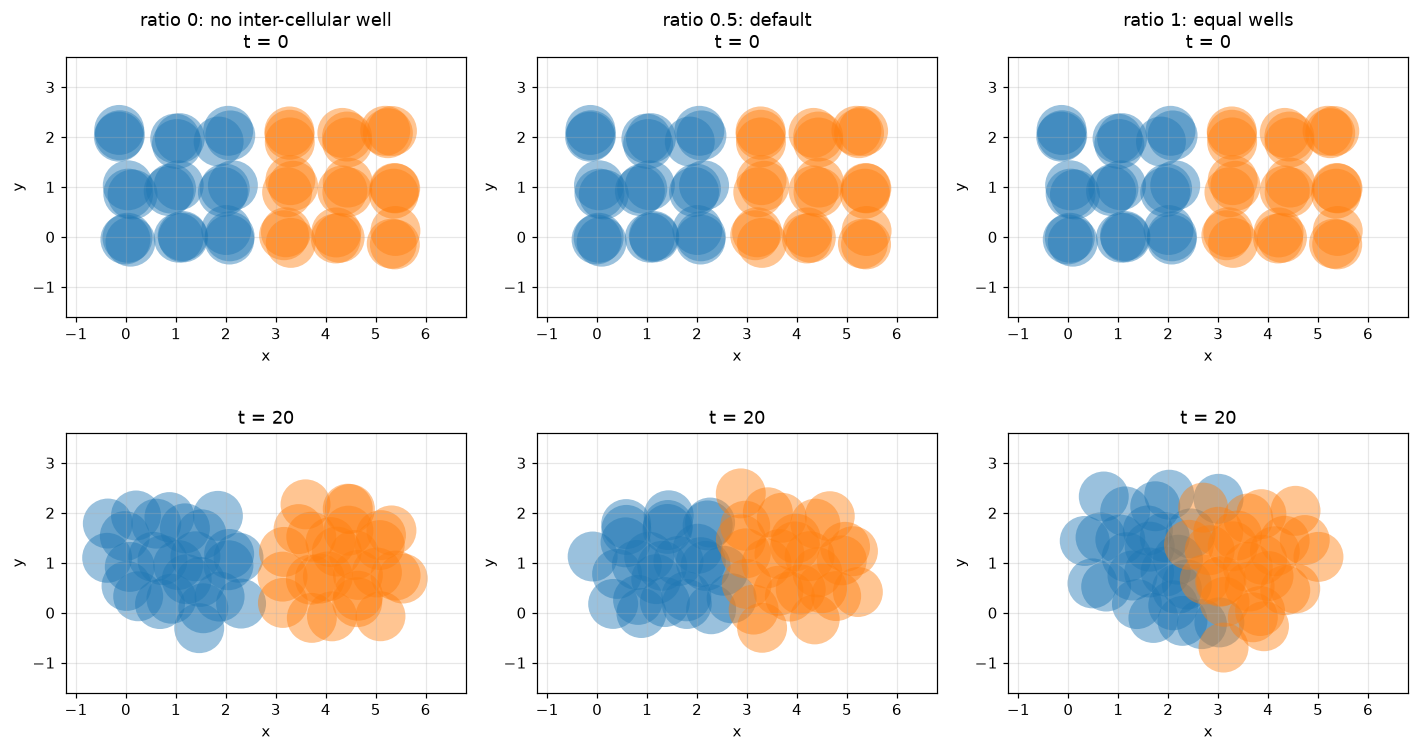

In [2]:
def draw(ax, snapshot, cell_of_agent, title):
    for cell in (0, 1):
        for x, y in snapshot[cell_of_agent == cell][:, :2]:
            ax.add_patch(plt.Circle((x, y), 0.5, color=cell_colors[cell], alpha=0.45, linewidth=0))
    ax.set(xlim=(-1.2, 6.8), ylim=(-1.6, 3.6), aspect="equal", xlabel="x", ylabel="y", title=title)


fig, axes = plt.subplots(2, len(ratios), figsize=(13, 7.2))
for column, ratio in enumerate(ratios):
    times, positions, cell_of_agent = runs[ratio]
    draw(axes[0, column], positions[0], cell_of_agent, f"{labels[ratio]}\nt = {times[0]:g}")
    draw(axes[1, column], positions[-1], cell_of_agent, f"t = {times[-1]:g}")
fig.tight_layout()

## Three numbers that tell the regimes apart

- **Centre distance:** distance between the centres of mass of the two cells.
- **Gap along the axis:** smallest x of the right cell minus largest x of the left cell.
  Positive means no element has passed an element of the other cell; negative means the cells interpenetrate.
- **Contacts:** pairs of elements from different cells closer than 1.3 equilibrium distances.
  For ratio 0 this counts pairs that are near each other but do not interact.

ratio              centre distance           gap along x        contacts
0               3.299 -> 3.299        1.024 -> 0.831          6 -> 5    
0.5             3.299 -> 2.552        1.024 -> 0.184          6 -> 24   
1               3.299 -> 1.970        1.024 -> -0.609         6 -> 48   


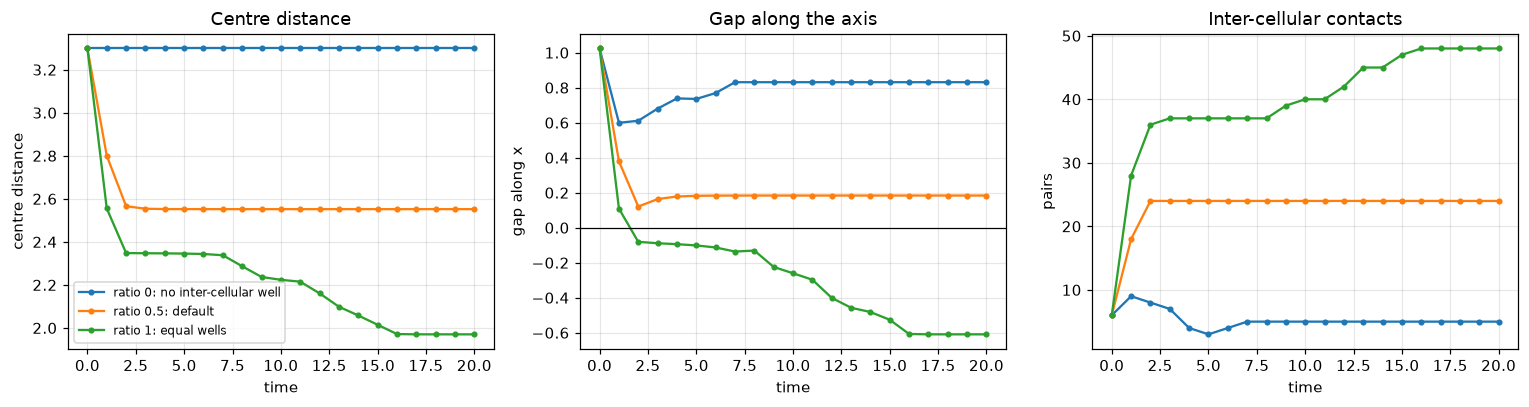

In [3]:
def measures(positions, cell_of_agent):
    first = positions[:, cell_of_agent == 0]
    second = positions[:, cell_of_agent == 1]
    centre_distance = np.linalg.norm(first.mean(axis=1) - second.mean(axis=1), axis=-1)
    gap = second[..., 0].min(axis=1) - first[..., 0].max(axis=1)
    pair_distances = np.linalg.norm(first[:, :, None, :] - second[:, None, :, :], axis=-1)
    contacts = (pair_distances < 1.3).sum(axis=(1, 2))
    return centre_distance, gap, contacts


fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
results = {}
for ratio in ratios:
    times, positions, cell_of_agent = runs[ratio]
    results[ratio] = measures(positions, cell_of_agent)
    for ax, series in zip(axes, results[ratio]):
        ax.plot(times, series, marker=".", label=labels[ratio])

axes[0].set(xlabel="time", ylabel="centre distance", title="Centre distance")
axes[1].set(xlabel="time", ylabel="gap along x", title="Gap along the axis")
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[2].set(xlabel="time", ylabel="pairs", title="Inter-cellular contacts")
axes[0].legend(fontsize=8)
fig.tight_layout()

print(f"{'ratio':<8}{'centre distance':>26}{'gap along x':>22}{'contacts':>16}")
for ratio in ratios:
    centre_distance, gap, contacts = results[ratio]
    print(f"{ratio:<8}{centre_distance[0]:>13.3f} -> {centre_distance[-1]:<9.3f}{gap[0]:>9.3f} -> {gap[-1]:<9.3f}{contacts[0]:>7d} -> {contacts[-1]:<5d}")

## Reading the result

The cell below asserts the three statements, so this notebook fails if the solver stops behaving this way.
The same statements are unit tests in `kernels/openmp_solver/tests/test_two_cells.cpp`.

In [4]:
centre_distance, gap, contacts = results["0"]
assert np.allclose(centre_distance, centre_distance[0], atol=1e-9), "ratio 0: the cells must not feel each other"

centre_distance, gap, contacts = results["0.5"]
assert centre_distance[-1] < centre_distance[0] - 0.5 and contacts[-1] > 3 * contacts[0], "ratio 0.5: the cells must adhere"
assert gap[-1] > 0.1, "ratio 0.5: the cells must not interpenetrate"

centre_distance, gap, contacts = results["1"]
assert gap[-1] < -0.1, "ratio 1: the cells must merge"

print("All three regimes confirmed.")

All three regimes confirmed.


- **Ratio 0 — the cells ignore each other.** The well depth multiplies the whole potential, repulsion
  included. With no inter-cellular well there is no volume exclusion between cells either: the centre
  distance does not change at all, and nothing would stop the cells from passing through each other.
  A small ratio therefore means cells that are weakly sticky *and* weakly solid towards each other.
- **Ratio 0.5 — the cells adhere and stay two cells.** They close the gap, build a contact interface and
  come to rest with the gap along the axis still positive.
- **Ratio 1 — the cells merge.** When both wells are equal nothing distinguishes an element of the other
  cell from one of its own; the system behaves exactly like a single cell of 54 elements and the gap turns negative.

Not shown here: intermediate ratios such as 0.1 or 0.25 behave like 0.5 but relax much more slowly
(they were still creeping at t = 30 in exploratory runs), and all of this is without thermal noise.
With noise, the ratio at which cells start to mix is expected to be lower.